# Kestrel customer feedback: analysis

Answers Q1-Q3 from `SPEC.md`. Scores and shares come from **silver** (`data/silver/feedback_silver.csv`);
themes and sentiment come from **gold** (`data/gold/feedback_gold.csv`: silver plus the AI labels from `03_label.py`,
prompt v1, checked against 120 hand labels by `04_evaluate.py`). Revenue is `reference/monthly_revenue.csv`.

Rules applied throughout (SPEC sections 6 and 11):
- Included rows only (`excluded == False`). Scores are `score_norm` (0-100, D1); never raw ratings across scales.
- **Dissatisfied** = score < 40, **at risk** = score <= 50 (D1). Ringwood also gets a <=6-of-10 sensitivity row (D2); the headline keeps the general rule.
- Shares are always shown with n. Cells with fewer than `THIN` responses are marked `*` and no trend or ranking is called on them.
- Themes use customer-voice comments only. Because 21% of staff write-ups were not tagged (voice check), theme results are also shown
  without Essendon and Ipswich, the two dealers with staff write-ups.
- Gaps (Penrith June 2026, Toowoomba Oct-Dec 2025, Shepparton after March 2026) are missing, not zero.

Run top to bottom from the repo root after `01_bronze.py` to `05_gold.py`. No API calls.

In [1]:
import math
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "SPEC.md").exists() else Path.cwd().parent
CHARTS = ROOT / "outputs" / "charts"
CHARTS.mkdir(parents=True, exist_ok=True)
THIN = 30          # rated responses below this are flagged as thin
pd.set_option("display.width", 200, "display.max_columns", 30)

silver = pd.read_csv(ROOT / "data" / "silver" / "feedback_silver.csv", dtype=str, keep_default_na=False)
dealers = pd.read_csv(ROOT / "reference" / "dealerships.csv")
revenue = pd.read_csv(ROOT / "reference" / "monthly_revenue.csv")
MONTHS = sorted(revenue["month"].unique())

inc = silver[silver["excluded"] == "False"].copy()
inc["score"] = pd.to_numeric(inc["score_norm"], errors="coerce")
rated = inc[inc["score"].notna()].copy()
rated["dis"] = rated["dissatisfied"] == "True"
rated["risk"] = rated["at_risk"] == "True"
name = dealers.set_index("dealer_code")["dealership_name"].str.replace("Kestrel ", "", regex=False)


def wilson(k, n, z=1.96):
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (c - h, c + h)


def summarise(g):
    n = len(g)
    lo, hi = wilson(int(g["dis"].sum()), n)
    return pd.Series({"n": n, "dissatisfied_share": g["dis"].mean(), "ci_low": lo, "ci_high": hi,
                      "at_risk_share": g["risk"].mean(), "mean_score": g["score"].mean(), "thin": n < THIN})


print(f"silver rows {len(silver)}, included {len(inc)}, rated {len(rated)}")

silver rows 7271, included 7070, rated 7060


## Sanity checks on the full AI-labelled set (before any analysis)

1. Theme distribution of every labelled comment (flag if `Other` is over 10%).
2. AI sentiment against the rating-based dissatisfied rate, by department (they are independent measures, so they should line up).
3. Label status of every included row, including the share with no comment.

In [2]:
import yaml

SETTINGS = yaml.safe_load((ROOT / "config" / "settings.yaml").read_text(encoding="utf-8"))
THEMES = SETTINGS["labels"]["themes"]
STAFF_WRITEUP_DEALERS = {"VIC03": "Essendon", "QLD03": "Ipswich"}
SANITY = ROOT / "outputs" / "sanity"
SANITY.mkdir(parents=True, exist_ok=True)

gold = pd.read_csv(ROOT / "data" / "gold" / "feedback_gold.csv", dtype=str, keep_default_na=False)
assert len(gold) == len(silver) and (gold["feedback_id"].values == silver["feedback_id"].values).all()
gi = gold[gold["excluded"] == "False"].copy()
gi["score"] = pd.to_numeric(gi["score_norm"], errors="coerce")
gi["dis"] = gi["dissatisfied"] == "True"
lab = gi[gi["label_status"] == "labelled"].copy()
assert set(lab["prompt_version"]) == {"v1"} and set(lab["prompt_sha"]) == {"d96a31004286"}

# 3. label status of included rows
status = gi["label_status"].value_counts().rename("rows").to_frame()
status["share"] = status["rows"] / len(gi)
status.loc["TOTAL"] = [len(gi), 1.0]
status.to_csv(SANITY / "label_status.csv")
print(f"included rows {len(gi)}: no_comment share {100*status.loc['no_comment','share']:.1f}%, "
      f"labelled {100*status.loc['labelled','share']:.1f}%")
print(status.round(3), "\n")

# 1. theme distribution
dist = pd.DataFrame({"n": lab["primary_theme"].value_counts().reindex(THEMES, fill_value=0)})
dist["share_primary"] = dist["n"] / len(lab)
dist["share_any_mention"] = [((lab["primary_theme"] == t) | (lab["secondary_theme"] == t)).mean() for t in THEMES]
dist.to_csv(SANITY / "theme_distribution.csv")
other = dist.loc["Other", "share_primary"]
print(f"labelled comments {len(lab)}; Other = {100*other:.1f}% -> {'FLAG: over 10%' if other > 0.10 else 'OK (10% or under)'}")
print(dist.round(3), "\n")

# 2. AI sentiment vs rating-based dissatisfied, by department (labelled comments that also have a rating)
lr = lab[lab["score"].notna()]
def sent_check(g):
    neg = g["sentiment"] == "negative"
    nm = g["sentiment"].isin(["negative", "mixed"])
    return pd.Series({"n": len(g), "dissatisfied_share": g["dis"].mean(), "ai_negative_share": neg.mean(),
                      "ai_negative_or_mixed_share": nm.mean(),
                      "dissatisfied_rows_ai_negative_or_mixed": nm[g["dis"]].mean(),
                      "not_dissatisfied_rows_ai_negative": neg[~g["dis"]].mean()})
sv = pd.concat([lr.groupby("department").apply(sent_check, include_groups=False),
                sent_check(lr).to_frame("All").T])
sv.to_csv(SANITY / "sentiment_vs_dissatisfied.csv")
print(f"labelled comments without a rating: {lab['score'].isna().sum()}")
sv.round(3)

included rows 7070: no_comment share 24.3%, labelled 72.8%
                 rows  share
label_status                
labelled       5150.0  0.728
no_comment     1721.0  0.243
skipped_voice   199.0  0.028
TOTAL          7070.0  1.000 

labelled comments 5150; Other = 1.6% -> OK (10% or under)
                              n  share_primary  share_any_mention
primary_theme                                                    
Staff attitude             1227          0.238              0.386
Communication and updates  1425          0.277              0.422
Wait time and turnaround   1025          0.199              0.285
Price and billing           657          0.128              0.178
Work quality and fix        322          0.063              0.093
Vehicle or product           14          0.003              0.038
Process and facilities      396          0.077              0.157
Other                        84          0.016              0.019 

labelled comments without a rating: 8


,n,dissatisfied_share,ai_negative_share,ai_negative_or_mixed_share,dissatisfied_rows_ai_negative_or_mixed,not_dissatisfied_rows_ai_negative
Parts,492.0,0.213,0.264,0.417,1.000,0.088
Sales,1048.0,0.134,0.148,0.251,1.000,0.036
Service,3602.0,0.331,0.359,0.516,0.996,0.082
All,5142.0,0.279,0.307,0.452,0.997,0.071


## Q2. How has feedback changed over the year?

Monthly dissatisfied share and mean score with response counts, for all dealers and for **like-for-like** dealers
(dealers with rated feedback in all 12 months, so mix changes from gaps do not look like trends).

In [3]:
present = rated.groupby("dealer_code")["month"].nunique()
lfl = sorted(present[present == len(MONTHS)].index)
not_lfl = sorted(set(dealers["dealer_code"]) - set(lfl))
print(f"like-for-like dealers: {len(lfl)} of {len(dealers)}; left out (a month missing): {', '.join(f'{c} {name[c]}' for c in not_lfl)}")

monthly_all = rated.groupby("month").apply(summarise, include_groups=False).reindex(MONTHS)
monthly_lfl = rated[rated["dealer_code"].isin(lfl)].groupby("month").apply(summarise, include_groups=False).reindex(MONTHS)
q2 = pd.concat({"all dealers": monthly_all, "like-for-like": monthly_lfl}, axis=1)
display_cols = [(g, c) for g in ("all dealers", "like-for-like") for c in ("n", "dissatisfied_share", "mean_score", "thin")]
q2.to_csv(ROOT / "outputs" / "q2_monthly.csv")
q2[display_cols].round(3)

like-for-like dealers: 21 of 24; left out (a month missing): NSW02 Penrith, QLD06 Toowoomba, VIC09 Shepparton


all dealers                                      like-for-like                                     
                  n dissatisfied_share mean_score   thin             n dissatisfied_share mean_score   thin
month                                                                                                      
2025-10         586              0.203     70.990  False           543              0.204     70.902  False
2025-11         540              0.189     71.944  False           493              0.191     71.957  False
2025-12         530              0.170     73.915  False           484              0.169     73.347  False
2026-01         516              0.223     68.120  False           453              0.227     67.826  False
2026-02         594              0.180     72.475  False           511              0.184     72.261  False
2026-03         613              0.220     69.545  False           530              0.211     70.388  False
2026-04         601              0.268     66.177  False           535              0.267     66.163  False
2026-05         615              0.237     67.589  False           544              0.230     67.862  False
2026-06         611              0.265     65.181  False           590              0.271     64.789  False
2026-07         613              0.227     68.054  False           549              0.226     68.064  False
2026-08         619              0.270     64.652  False           531              0.275     64.538  False
2026-09         622              0.227     68.297  False           543              0.232     67.644  False

dealer-months with no feedback: VIC09 2026-04, VIC09 2026-05, VIC09 2026-06, VIC09 2026-07, VIC09 2026-08, VIC09 2026-09, NSW02 2026-06, QLD06 2025-10, QLD06 2025-11, QLD06 2025-12


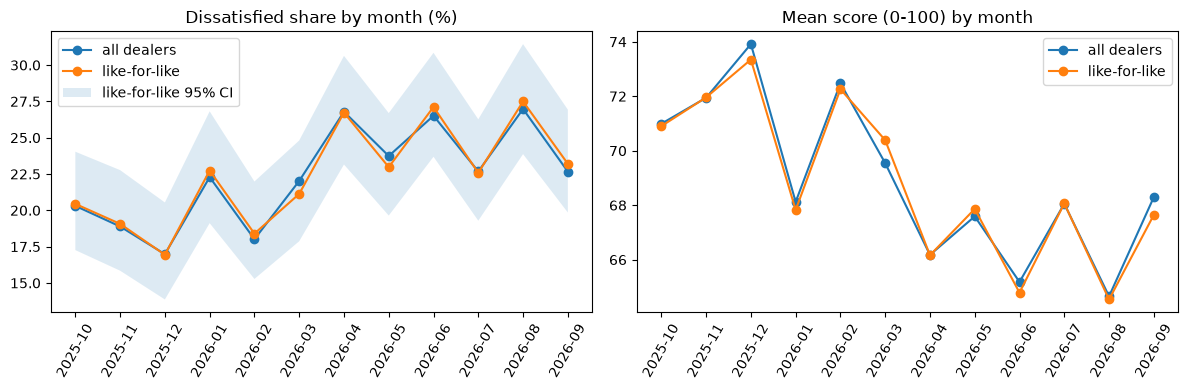

In [4]:
# gaps: dealer-months with no rated feedback (shown as missing, not zero)
grid = rated.groupby(["dealer_code", "month"]).size().unstack().reindex(index=dealers["dealer_code"], columns=MONTHS)
gaps = grid.isna().stack()
gaps = gaps[gaps].index.tolist()
print("dealer-months with no feedback:", ", ".join(f"{d} {m}" for d, m in gaps))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for label, m in (("all dealers", monthly_all), ("like-for-like", monthly_lfl)):
    ax[0].plot(m.index, 100 * m["dissatisfied_share"], marker="o", label=label)
    ax[1].plot(m.index, m["mean_score"], marker="o", label=label)
lo, hi = 100 * monthly_lfl["ci_low"], 100 * monthly_lfl["ci_high"]
ax[0].fill_between(monthly_lfl.index, lo, hi, alpha=0.15, label="like-for-like 95% CI")
ax[0].set_title("Dissatisfied share by month (%)")
ax[1].set_title("Mean score (0-100) by month")
for a in ax:
    a.tick_params(axis="x", rotation=60)
    a.legend()
plt.tight_layout()
plt.savefig(CHARTS / "q2_monthly.png", dpi=120)
plt.show()

In [5]:
# first quarter vs last quarter, like-for-like, naive interval (treats every response as independent)
FIRST, LAST = MONTHS[:3], MONTHS[-3:]
def period(ms, dealers):
    g = rated[rated["dealer_code"].isin(dealers) & rated["month"].isin(ms)]
    return int(g["dis"].sum()), len(g)

(k1, n1), (k2, n2) = period(FIRST, lfl), period(LAST, lfl)
p1, p2 = k1 / n1, k2 / n2
se = math.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
print(f"Q4 2025 {100*p1:.1f}% (n={n1}) -> Q3 2026 {100*p2:.1f}% (n={n2}); "
      f"change {100*(p2-p1):+.1f} pts, naive 95% CI {100*(p2-p1-1.96*se):+.1f} to {100*(p2-p1+1.96*se):+.1f}")
print("Naive CI ignores that responses cluster within dealers; the robustness checks below decide whether this is a finding.")

Q4 2025 18.9% (n=1520) -> Q3 2026 24.4% (n=1623); change +5.5 pts, naive 95% CI +2.6 to +8.4
Naive CI ignores that responses cluster within dealers; the robustness checks below decide whether this is a finding.


### Q2 robustness: does the rise survive?

The naive interval treats 3,000+ responses as independent, but they cluster in 21 dealers whose collection habits differ.
Before calling the rise a finding:

1. **Exclude Ringwood (VIC02).** It moved from a 1-5 to a 1-10 scale in Feb 2026, so its dissatisfied threshold changed between the two periods.
2. **Which dealers drive it.** Each dealer's contribution to the pooled change, and the change with each dealer left out.
3. **Dealer-clustered interval.** Bootstrap by resampling dealers (seed 42, 5,000 draws), plus a dealer-level mean change with a t-interval.

The rise counts as a finding only if the clustered interval excludes 0 with and without Ringwood, and no single dealer's removal erases it.

In [6]:
import numpy as np

def period_table(dealers):
    g = rated[rated["dealer_code"].isin(dealers) & rated["month"].isin(FIRST + LAST)].copy()
    g["period"] = np.where(g["month"].isin(FIRST), "first", "last")
    t = g.groupby(["dealer_code", "period"])["dis"].agg(["sum", "size"]).unstack(fill_value=0)
    t.columns = [f"{a}_{b}" for a, b in t.columns]
    return t

def pooled_change(t):
    return t["sum_last"].sum() / t["size_last"].sum() - t["sum_first"].sum() / t["size_first"].sum()

def cluster_bootstrap(t, reps=5000, seed=42):
    rng = np.random.default_rng(seed)
    k1, n1, k2, n2 = (t[c].to_numpy() for c in ("sum_first", "size_first", "sum_last", "size_last"))
    idx = rng.integers(0, len(t), size=(reps, len(t)))
    d = k2[idx].sum(1) / n2[idx].sum(1) - k1[idx].sum(1) / n1[idx].sum(1)
    return np.percentile(d, [2.5, 97.5])

def dealer_mean_change(t):
    ch = t["sum_last"] / t["size_last"] - t["sum_first"] / t["size_first"]
    m, sd, k = ch.mean(), ch.std(ddof=1), len(ch)
    tcrit = {19: 2.093, 20: 2.086, 21: 2.080}.get(k - 1, 2.09)
    return m, (m - tcrit * sd / math.sqrt(k), m + tcrit * sd / math.sqrt(k)), int((ch > 0).sum()), k

rows = []
for label, ds in (("like-for-like (all)", lfl), ("like-for-like excluding Ringwood", [d for d in lfl if d != "VIC02"])):
    t = period_table(ds)
    ch = pooled_change(t)
    lo, hi = cluster_bootstrap(t)
    m, (mlo, mhi), up, k = dealer_mean_change(t)
    loo = [pooled_change(t.drop(d)) for d in t.index]
    rows.append({"set": label, "dealers": k, "n_first": int(t["size_first"].sum()), "n_last": int(t["size_last"].sum()),
                 "first_share": t["sum_first"].sum() / t["size_first"].sum(), "last_share": t["sum_last"].sum() / t["size_last"].sum(),
                 "pooled_change_pts": 100 * ch, "cluster_boot_ci_pts": f"{100*lo:+.1f} to {100*hi:+.1f}",
                 "dealer_mean_change_pts": 100 * m, "dealer_mean_ci_pts": f"{100*mlo:+.1f} to {100*mhi:+.1f}",
                 "dealers_rising": f"{up} of {k}", "leave_one_out_min_pts": 100 * min(loo), "leave_one_out_max_pts": 100 * max(loo),
                 "survives": bool(lo > 0 and mlo > 0 and min(loo) > 0)})
robust = pd.DataFrame(rows)
robust.to_csv(ROOT / "outputs" / "q2_robustness.csv", index=False)
robust.round(3).T

,0,1
set,like-for-like (all),like-for-like excluding Ringwood
dealers,21,20
n_first,1520,1420
n_last,1623,1496
first_share,0.189,0.191
last_share,0.244,0.249
pooled_change_pts,5.518,5.849
cluster_boot_ci_pts,+1.0 to +10.6,+1.0 to +11.2
dealer_mean_change_pts,4.835,4.971
dealer_mean_ci_pts,+0.5 to +9.2,+0.4 to +9.6


In [7]:
# which dealers drive it: contribution to the pooled change (contributions sum to the pooled change)
t = period_table(lfl)
N1, N2 = t["size_first"].sum(), t["size_last"].sum()
drv = pd.DataFrame({
    "dealer": name.reindex(t.index),
    "n_first": t["size_first"], "share_first": t["sum_first"] / t["size_first"],
    "n_last": t["size_last"], "share_last": t["sum_last"] / t["size_last"],
})
drv["change_pts"] = 100 * (drv["share_last"] - drv["share_first"])
drv["contribution_pts"] = 100 * (t["sum_last"] / N2 - t["sum_first"] / N1)
drv["change_without_dealer_pts"] = [100 * pooled_change(t.drop(d)) for d in t.index]
drv = drv.sort_values("contribution_pts", ascending=False)
drv.to_csv(ROOT / "outputs" / "q2_dealer_drivers.csv")
print(f"pooled change {100*pooled_change(t):+.1f} pts = sum of contributions {drv['contribution_pts'].sum():+.1f}")
top = drv.head(5)
print("top 5 contributors:", ", ".join(f"{r.dealer} {r.contribution_pts:+.2f}" for r in top.itertuples()),
      f"= {top['contribution_pts'].sum():+.1f} pts of {100*pooled_change(t):+.1f}")
drv.round(3)

pooled change +5.5 pts = sum of contributions +5.5
top 5 contributors: Parramatta +2.02, Dandenong +1.27, Liverpool +0.57, Southport +0.57, Chatswood +0.50 = +4.9 pts of +5.5


,dealer,n_first,share_first,n_last,share_last,change_pts,contribution_pts,change_without_dealer_pts
dealer_code,,,,,,,,
NSW01,Parramatta,120,0.142,116,0.440,29.799,2.024,3.607
VIC01,Dandenong,122,0.172,129,0.333,16.120,1.268,4.601
NSW04,Liverpool,82,0.146,85,0.259,11.248,0.566,5.194
QLD04,Southport,60,0.200,67,0.328,12.836,0.566,5.200
NSW03,Chatswood,68,0.176,78,0.269,9.276,0.504,5.332
VIC08,Bendigo,30,0.133,36,0.333,20.000,0.476,5.203
QLD03,Ipswich,69,0.116,56,0.268,15.192,0.398,5.086
VIC02,Ringwood,100,0.160,127,0.181,2.110,0.364,5.849
VIC05,Box Hill,64,0.234,85,0.247,1.268,0.307,5.701


In [8]:
# is it a department-mix effect? change within each department (like-for-like dealers)
g = rated[rated["dealer_code"].isin(lfl) & rated["month"].isin(FIRST + LAST)].copy()
g["period"] = np.where(g["month"].isin(FIRST), "Q4 2025", "Q3 2026")
mix = g.groupby(["department", "period"])["dis"].agg(["mean", "size"]).unstack()
mix.columns = [f"{a} {b}" for a, b in mix.columns]
mix["change_pts"] = 100 * (mix["mean Q3 2026"] - mix["mean Q4 2025"])
share = g.groupby("period")["department"].value_counts(normalize=True).unstack(0)
print("department share of responses:"); print(share.round(3))
mix.round(3)

department share of responses:
period      Q3 2026  Q4 2025
department                  
Parts         0.105    0.099
Sales         0.203    0.226
Service       0.691    0.675


,mean Q3 2026,mean Q4 2025,size Q3 2026,size Q4 2025,change_pts
department,,,,,
Parts,0.088,0.147,171,150,-5.895
Sales,0.133,0.078,330,344,5.484
Service,0.300,0.232,1122,1026,6.839


### Q2 check: are the Parramatta and Dandenong jumps a collection change?

Both dealers jump in **May 2026**. Parramatta's monthly files gain a `Booking ref` column from May, and Dandenong's May tab has an extra banner row.
This check compares Oct 2025-Apr 2026 with May-Sep 2026 at each dealer and at the other 19 like-for-like dealers:

- **Template / collection signals:** header per file or tab, banner notes, fill rate of each column (counts only, read-only from the source files).
- **Volume:** responses per month and per 1,000 transactions.
- **Where the extra responses come from:** dissatisfied vs not-dissatisfied responses per month. Extra complaints logged on top of the usual feedback leave the not-dissatisfied count flat; a real decline moves customers from satisfied to dissatisfied, so that count falls.
- **Content:** share of dissatisfied comments that mention the booking system (keyword signal only: online, booking system, website, portal, app, system).

In [9]:
import re
import openpyxl

MAY = "2026-05"
bronze = pd.read_csv(ROOT / "data" / "bronze" / "bronze_rows.csv", dtype=str, keep_default_na=False)
for fam in ("parramatta", "dandenong"):
    hb = bronze[(bronze["family"] == fam) & bronze["row_class"].isin(["header", "banner"])]
    hdr = hb[hb["row_class"] == "header"].groupby(["source_file", "source_sheet"])["note_text"].first()
    print(f"{fam}: {hdr.nunique()} distinct header(s):")
    for h, g in hdr.groupby(hdr):
        print(f"   {h}  <- {', '.join(s if s != '(csv)' else f for f, s in g.index)}")
    extra = hb[(hb["row_class"] == "banner") & ~hb["note_text"].str.match(r"Kestrel |Month: ")]
    for r in extra.itertuples():
        print(f"   banner note [{r.source_sheet}] row {r.source_row}: {r.note_text}")

def fill_rates(path, sheet, header_row):
    wb = openpyxl.load_workbook(path, read_only=True, data_only=True)
    ws = wb[sheet] if sheet else wb.active
    rows = list(ws.iter_rows(values_only=True))
    wb.close()
    h = [str(c).strip() if c else "" for c in rows[header_row - 1]]
    data = [r for r in rows[header_row:] if any(v not in (None, "") for v in r)]
    return {c: sum(1 for r in data if i < len(r) and r[i] not in (None, "")) / len(data) for i, c in enumerate(h) if c}

fr = {}
for f in sorted((ROOT / "feedback").glob("Parramatta_Feedback_*.xlsx")):
    fr[("Parramatta", f.stem[-7:])] = fill_rates(f, None, 1)
dand = ROOT / "feedback" / "Dandenong Customer Feedback 2025-26.xlsx"
for m in MONTHS:
    tab = pd.Period(m).strftime("%b %y")
    fr[("Dandenong", m)] = fill_rates(dand, tab, 5 if tab == "May 26" else 4)
fill = pd.DataFrame(fr).T
fill.index.names = ["dealer", "month"]
fill = fill.drop(columns=[c for c in ("Date", "Department", "Dept", "Rating", "Rating (1-5)") if c in fill])
print("\nColumn fill rates (share of rows with a value; values not shown):")
fill.round(2)

parramatta: 2 distinct header(s):
   Date | Cust No | Mobile | Department | Booking ref | Rating | Comments | Staff  <- May 26, Jun 26, Jul 26, Aug 26, Sep 26
   Date | Cust No | Mobile | Department | Rating | Comments | Staff  <- Oct 25, Nov 25, Dec 25, Jan 26, Feb 26, Mar 26, Apr 26
dandenong: 1 distinct header(s):
   Date | Dept | Customer | Vehicle | Rego | Rating (1-5) | Comments | Action taken  <- Apr 26, Aug 26, Dec 25, Feb 26, Jan 26, Jul 26, Jun 26, Mar 26, May 26, Nov 25, Oct 25, Sep 26
   banner note [May 26] row 3: NOTE: new online booking system went live 5 May. Expect some teething issues - log everything!



Column fill rates (share of rows with a value; values not shown):


Cust No  Mobile  Comments  Staff  Booking ref  Customer  Vehicle  Rego  Action taken
dealer     month                                                                                        
Parramatta 2025-10      1.0    0.89      0.68    1.0          NaN       NaN      NaN   NaN           NaN
           2025-11      1.0    0.97      0.72    1.0          NaN       NaN      NaN   NaN           NaN
           2025-12      1.0    0.89      0.76    1.0          NaN       NaN      NaN   NaN           NaN
           2026-01      1.0    0.86      0.81    1.0          NaN       NaN      NaN   NaN           NaN
           2026-02      1.0    0.85      0.70    1.0          NaN       NaN      NaN   NaN           NaN
           2026-03      1.0    0.88      0.75    1.0          NaN       NaN      NaN   NaN           NaN
           2026-04      1.0    0.94      0.76    1.0          NaN       NaN      NaN   NaN           NaN
           2026-05      1.0    0.78      0.69    1.0          1.0       NaN      NaN   NaN           NaN
           2026-06      1.0    0.78      0.78    1.0          1.0       NaN      NaN   NaN           NaN
           2026-07      1.0    0.76      0.84    1.0          1.0       NaN      NaN   NaN           NaN
           2026-08      1.0    0.85      0.79    1.0          1.0       NaN      NaN   NaN           NaN
           2026-09      1.0    0.92      0.80    1.0          1.0       NaN      NaN   NaN           NaN
Dandenong  2025-10      NaN     NaN      0.78    NaN          NaN       1.0     0.76  0.88          0.37
           2025-11      NaN     NaN      0.77    NaN          NaN       1.0     0.86  0.91          0.20
           2025-12      NaN     NaN      0.81    NaN          NaN       1.0     0.97  0.89          0.22
           2026-01      NaN     NaN      0.58    NaN          NaN       1.0     0.92  0.83          0.19
           2026-02      NaN     NaN      0.62    NaN          NaN       1.0     0.94  0.91          0.28
           2026-03      NaN     NaN      0.61    NaN          NaN       1.0     0.97  0.84          0.16
           2026-04      NaN     NaN      0.78    NaN          NaN       1.0     0.82  0.88          0.38
           2026-05      NaN     NaN      0.83    NaN          NaN       1.0     0.88  0.80          0.54
           2026-06      NaN     NaN      0.81    NaN          NaN       1.0     0.96  0.91          0.58
           2026-07      NaN     NaN      0.83    NaN          NaN       1.0     0.94  0.77          0.44
           2026-08      NaN     NaN      0.89    NaN          NaN       1.0     0.84  0.84          0.48
           2026-09      NaN     NaN      0.81    NaN          NaN       1.0     0.92  0.84          0.46

In [10]:
BK = re.compile(r"\bonline\b|\bbooking system\b|\bnew system\b|\bwebsite\b|\bportal\b|\bapp\b|\bbook(?:ed|ing)? online\b|\bsystem\b", re.I)
g = rated[rated["dealer_code"].isin(lfl)].copy()
g["after"] = np.where(g["month"] >= MAY, "May-Sep 2026", "Oct 2025-Apr 2026")
g["who"] = g["dealer_code"].map({"NSW01": "Parramatta", "VIC01": "Dandenong"}).fillna("other 19 like-for-like")
g["bk"] = g["comment_clean"].str.contains(BK)
txn = revenue.assign(txn=revenue[["vehicles_sold", "service_jobs", "parts_transactions"]].sum(axis=1)).set_index(["dealer_code", "month"])["txn"]
g["txn"] = [txn[(d, m)] for d, m in zip(g["dealer_code"], g["month"])]

def collect(d):
    months = d["month"].nunique()
    per_txn = 1000 * len(d) / d.drop_duplicates(["dealer_code", "month"])["txn"].sum()
    lo, hi = wilson(int(d["dis"].sum()), len(d))
    return pd.Series({"months": months, "responses_per_month": len(d) / months, "per_1000_txn": per_txn,
                      "dissatisfied_per_month": d["dis"].sum() / months, "not_dissatisfied_per_month": (~d["dis"]).sum() / months,
                      "dissatisfied_share": d["dis"].mean(), "ci": f"{100*lo:.0f}-{100*hi:.0f}%",
                      "comment_rate": (d["has_text"] == "True").mean(), "service_share": (d["department"] == "Service").mean(),
                      "booking_kw_share_of_dissatisfied": d.loc[d["dis"], "bk"].mean(),
                      "dissatisfied_share_excl_booking_kw": d.loc[~d["bk"], "dis"].mean()})

collection = g.groupby(["who", "after"]).apply(collect, include_groups=False)
collection.to_csv(ROOT / "outputs" / "q2_collection_check.csv")
collection.round(3).T

who                                   Dandenong                     Parramatta                   other 19 like-for-like                  
after                              May-Sep 2026 Oct 2025-Apr 2026 May-Sep 2026 Oct 2025-Apr 2026           May-Sep 2026 Oct 2025-Apr 2026
months                                        5                 7            5                 7                      5                 7
responses_per_month                        44.6            37.286         42.0            38.429                  464.8           431.286
per_1000_txn                             30.623            25.965       29.252            26.502                 25.764            25.769
dissatisfied_per_month                     15.8             6.286         16.8               7.0                  103.6            92.286
not_dissatisfied_per_month                 28.8              31.0         25.2            31.429                  361.2             339.0
dissatisfied_share                        0.354             0.169          0.4             0.182                  0.223             0.214
ci                                       29-42%            13-22%       34-47%            14-23%                 21-24%            20-23%
comment_rate                              0.834             0.716        0.776              0.74                  0.759             0.756
service_share                             0.655             0.663        0.657             0.643                  0.676             0.696
booking_kw_share_of_dissatisfied          0.177             0.023        0.202             0.082                  0.031             0.022
dissatisfied_share_excl_booking_kw        0.316             0.167        0.353              0.17                  0.219             0.211

In [11]:
# effect on the Q2 group result: like-for-like change with each / both dealers removed
t = period_table(lfl)
wo = []
for drop in (["NSW01"], ["VIC01"], ["NSW01", "VIC01"]):
    tt = t.drop(drop)
    lo, hi = cluster_bootstrap(tt)
    wo.append({"without": " + ".join(name[d] for d in drop), "dealers": len(tt), "change_pts": 100 * pooled_change(tt),
               "cluster_ci_low_pts": 100 * lo, "cluster_ci_high_pts": 100 * hi})
    print(f"without {', '.join(name[d] for d in drop):22s}: change {100*pooled_change(tt):+.1f} pts, dealer-clustered 95% CI {100*lo:+.1f} to {100*hi:+.1f}")
pd.DataFrame(wo).to_csv(ROOT / "outputs" / "q2_without_dealers.csv", index=False)

without Parramatta            : change +3.6 pts, dealer-clustered 95% CI +0.2 to +7.2
without Dandenong             : change +4.6 pts, dealer-clustered 95% CI +0.3 to +9.9
without Parramatta, Dandenong : change +2.4 pts, dealer-clustered 95% CI -0.5 to +5.7


In [12]:
# Booking-system evidence from two sources: the keyword search above AND the AI theme label.
# Process and facilities is the weakest-evaluated theme (outputs/evaluation/per_theme.csv), so the label is
# corroboration for the keywords, not a measure on its own.
gl = g.merge(gold[["feedback_id", "label_status", "primary_theme", "secondary_theme"]], on="feedback_id", how="left")
gl = gl[gl["dis"] & (gl["label_status"] == "labelled")]
PF = "Process and facilities"
def booking(d):
    pf = d["primary_theme"] == PF
    pf_any = pf | (d["secondary_theme"] == PF)
    return pd.Series({"dissatisfied_labelled_n": len(d), "keyword_share": d["bk"].mean(),
                      "process_primary_share": pf.mean(), "process_any_mention_share": pf_any.mean(),
                      "keyword_and_process_any_share": (d["bk"] & pf_any).mean(),
                      "keyword_rows_labelled_process_any": pf_any[d["bk"]].mean() if d["bk"].any() else float("nan")})
book = gl.groupby(["who", "after"]).apply(booking, include_groups=False)
book.to_csv(ROOT / "outputs" / "q2_booking_themes.csv")
ev = pd.read_csv(ROOT / "outputs" / "evaluation" / "per_theme.csv").set_index("class").loc[PF]
print(f"{PF} in the evaluation: precision {ev['precision']:.2f}, recall {ev['recall']:.2f}, hand-labelled n={int(ev['support_human'])} (weakest theme)")
book.round(3).T

Process and facilities in the evaluation: precision 0.56, recall 0.71, hand-labelled n=7 (weakest theme)


who                                  Dandenong                     Parramatta                   other 19 like-for-like                  
after                             May-Sep 2026 Oct 2025-Apr 2026 May-Sep 2026 Oct 2025-Apr 2026           May-Sep 2026 Oct 2025-Apr 2026
dissatisfied_labelled_n                 77.000            42.000       78.000            45.000                460.000           581.000
keyword_share                            0.182             0.024        0.218             0.089                  0.026             0.024
process_primary_share                    0.221             0.143        0.205             0.133                  0.102             0.088
process_any_mention_share                0.312             0.262        0.321             0.333                  0.226             0.196
keyword_and_process_any_share            0.182             0.024        0.192             0.067                  0.015             0.012
keyword_rows_labelled_process_any        1.000             1.000        0.882             0.750                  0.583             0.500

In [13]:
# Parramatta: which themes rose among dissatisfied comments, before vs from May 2026 (primary and any mention, with n)
p = gl[gl["who"] == "Parramatta"]
pt = {}
for per, d in p.groupby("after"):
    pt[(per, "n")] = pd.Series(len(d), index=THEMES)
    pt[(per, "primary")] = d["primary_theme"].value_counts(normalize=True).reindex(THEMES, fill_value=0)
    pt[(per, "any mention")] = pd.Series({t: ((d["primary_theme"] == t) | (d["secondary_theme"] == t)).mean() for t in THEMES})
pt = pd.DataFrame(pt)
B, A = "Oct 2025-Apr 2026", "May-Sep 2026"
pt[("change_pts", "primary")] = 100 * (pt[(A, "primary")] - pt[(B, "primary")])
pt[("change_pts", "any mention")] = 100 * (pt[(A, "any mention")] - pt[(B, "any mention")])
pt = pt.sort_values(("change_pts", "primary"), ascending=False)
pt.to_csv(ROOT / "outputs" / "q2_parramatta_themes.csv")
print(f"Parramatta dissatisfied labelled comments: n={len(p[p['after'] == B])} before, n={len(p[p['after'] == A])} from May 2026 (small: read changes under ~10 points with care)")
pt.round(3)


Parramatta dissatisfied labelled comments: n=45 before, n=78 from May 2026 (small: read changes under ~10 points with care)


May-Sep 2026                     Oct 2025-Apr 2026                     change_pts            
                                     n primary any mention                 n primary any mention    primary any mention
Process and facilities              78   0.205       0.321                45   0.133       0.333      7.179      -1.282
Staff attitude                      78   0.077       0.128                45   0.067       0.178      1.026      -4.957
Wait time and turnaround            78   0.295       0.410                45   0.289       0.311      0.598       9.915
Vehicle or product                  78   0.000       0.026                45   0.000       0.000      0.000       2.564
Other                               78   0.000       0.000                45   0.000       0.000      0.000       0.000
Price and billing                   78   0.141       0.167                45   0.156       0.222     -1.453      -5.556
Work quality and fix                78   0.115       0.154                45   0.133       0.267     -1.795     -11.282
Communication and updates           78   0.167       0.436                45   0.222       0.333     -5.556      10.256

**Reading (from the outputs above; re-check if the data changes):**

- **Common cause.** Both jumps start in May 2026, when a new online booking system went live. Dandenong's May tab says so
  ("new online booking system went live 5 May ... log everything!"). Parramatta added a `Booking ref` column, filled on every row, the same month.
  Dissatisfied comments mentioning the booking system rise from a few percent to about a fifth at both dealers; the other 19 dealers barely move.
- **Dandenong: suspected partly a collection change.** The note tells staff to "log everything". Volume rises by about a fifth, and the
  extra responses are almost all dissatisfied while not-dissatisfied responses stay about flat. That pattern fits more complaints being logged, on top of real booking problems.
- **Parramatta: looks like a real change, not a collection change.** Volume barely moves, comment rate, department mix and column fill rates are stable,
  and not-dissatisfied responses fall while dissatisfied ones rise, so customers moved from satisfied to dissatisfied.
  The new column records the booking but shows no change in who is surveyed.
- **Group result.** Without both dealers, the like-for-like rise is small and its clustered interval includes zero (see the cell above),
  so the Q2 "rise" is mainly a booking-system effect at two dealers, not a group-wide trend.
- **Confirm by asking** both dealers when the booking system went live, and whether the way feedback was collected changed in May (Dandenong's "log everything").

## Q1. Where is negative feedback concentrated (dealer and department)?

Dissatisfied share with n and 95% Wilson interval. Thin cells are flagged, not ranked.

In [14]:
by_dealer = rated.groupby("dealer_code").apply(summarise, include_groups=False)
by_dealer.insert(0, "dealer", name.reindex(by_dealer.index))
by_dealer.to_csv(ROOT / "outputs" / "q1_by_dealer.csv")
by_dealer.sort_values("dissatisfied_share", ascending=False).round(3)

,dealer,n,dissatisfied_share,ci_low,ci_high,at_risk_share,mean_score,thin
dealer_code,,,,,,,,
NSW01,Parramatta,479,0.278,0.239,0.319,0.405,64.770,False
QLD07,Rockhampton,202,0.257,0.202,0.322,0.401,63.119,False
VIC01,Dandenong,484,0.254,0.217,0.295,0.382,65.909,False
QLD04,Southport,250,0.252,0.202,0.309,0.368,66.000,False
NSW03,Chatswood,278,0.248,0.201,0.302,0.335,67.806,False
VIC05,Box Hill,309,0.239,0.195,0.290,0.359,65.777,False
QLD01,Chermside,460,0.237,0.200,0.278,0.374,66.902,False
QLD06,Toowoomba,248,0.234,0.185,0.290,0.343,68.347,False
VIC04,Frankston,308,0.234,0.190,0.284,0.338,68.831,False


In [15]:
by_dd = rated.groupby(["dealer_code", "department"]).apply(summarise, include_groups=False)
cell = by_dd.apply(lambda r: f"{100*r.dissatisfied_share:.0f}% (n={int(r.n)})" + (" *" if r.thin else ""), axis=1)
table = cell.unstack("department").reindex(columns=["Sales", "Service", "Parts"])
table.insert(0, "dealer", name.reindex(table.index))
print("* = fewer than", THIN, "rated responses")
by_dd.to_csv(ROOT / "outputs" / "q1_by_dealer_department.csv")
table

* = fewer than 30 rated responses


department,dealer,Sales,Service,Parts
dealer_code,,,,
NSW01,Parramatta,11% (n=122),36% (n=311),13% (n=46)
NSW02,Penrith,14% (n=115),25% (n=285),20% (n=54)
NSW03,Chatswood,15% (n=66),31% (n=180),9% (n=32)
NSW04,Liverpool,18% (n=80),24% (n=206),12% (n=25) *
NSW05,Newcastle,10% (n=69),26% (n=204),23% (n=30)
NSW06,Wollongong,4% (n=71),20% (n=191),22% (n=23) *
NSW07,Tamworth,12% (n=32),17% (n=96),20% (n=5) *
QLD01,Chermside,13% (n=109),28% (n=314),22% (n=37)
QLD02,Springwood,4% (n=74),24% (n=195),7% (n=29) *


In [16]:
by_dept = rated.groupby("department").apply(summarise, include_groups=False).round(3)
by_dept.to_csv(ROOT / "outputs" / "q1_by_department.csv")
by_dept

,n,dissatisfied_share,ci_low,ci_high,at_risk_share,mean_score,thin
department,,,,,,,
Parts,697,0.162,0.137,0.191,0.284,73.797,False
Sales,1527,0.101,0.087,0.117,0.164,81.664,False
Service,4836,0.272,0.260,0.285,0.389,64.041,False


In [17]:
# D2 sensitivity: Ringwood at risk at <=5 of 10 (headline, D1) vs <=6 of 10 (sensitivity only)
ring = rated[rated["rating_scale"] == "num_1_10"]
r = ring["rating_raw"].astype(int)
print(f"Ringwood 1-10 rows n={len(ring)}: at risk headline <=5 {100*(r<=5).mean():.1f}% | sensitivity <=6 {100*(r<=6).mean():.1f}%")
pd.DataFrame([{"rows_1_10": len(ring), "at_risk_headline_le5": (r <= 5).mean(), "at_risk_sensitivity_le6": (r <= 6).mean()}]).to_csv(
    ROOT / "outputs" / "d2_ringwood_sensitivity.csv", index=False)

# V3: Bendigo Sales with and without the inferred 'S' code rows (D3)
b = rated[(rated["dealer_code"] == "VIC08")]
print("Bendigo by department:", b.groupby("department")["dis"].agg(["mean", "size"]).round(3).to_dict("index"))
print(f"Group Sales dissatisfied: all {100*rated[rated.department=='Sales']['dis'].mean():.1f}% vs without inferred rows "
      f"{100*rated[(rated.department=='Sales') & (rated.dept_inferred!='True')]['dis'].mean():.1f}%")

Ringwood 1-10 rows n=321: at risk headline <=5 25.5% | sensitivity <=6 32.1%
Bendigo by department: {'Parts': {'mean': 0.2, 'size': 15}, 'Sales': {'mean': 0.031, 'size': 32}, 'Service': {'mean': 0.258, 'size': 97}}
Group Sales dissatisfied: all 10.1% vs without inferred rows 10.2%


### Q1 drivers by theme

Theme share of **dissatisfied** comments (score < 40, customer voice, AI-labelled), shown with n.
`primary` counts each comment once by its main theme; `any mention` counts primary or secondary, so rows add to more than 100% (sensitivity).
Each table is repeated without Essendon and Ipswich. `*` = fewer than `THIN` dissatisfied comments: read, but do not rank.

In [18]:
dis = lab[lab["dis"]].copy()
SUBSETS = {"all dealers": dis, "without Essendon and Ipswich": dis[~dis["dealer_code"].isin(STAFF_WRITEUP_DEALERS)]}

def theme_shares(d, basis):
    if basis == "primary":
        s = d["primary_theme"].value_counts(normalize=True).reindex(THEMES, fill_value=0)
    else:
        s = pd.Series({t: ((d["primary_theme"] == t) | (d["secondary_theme"] == t)).mean() for t in THEMES})
    return pd.concat([pd.Series({"n": len(d), "thin": len(d) < THIN}), s])

def fmt(t):
    out = t[THEMES].map(lambda v: f"{100*v:.0f}%")
    out.insert(0, "n", t["n"].astype(int).astype(str) + t["thin"].map({True: " *", False: ""}))
    return out

rows = {}
for sub, d in SUBSETS.items():
    for dept in ["All", "Sales", "Service", "Parts"]:
        dd = d if dept == "All" else d[d["department"] == dept]
        for basis in ["primary", "any mention"]:
            rows[(dept, basis, sub)] = theme_shares(dd, basis)
q1_theme_dept = pd.DataFrame(rows).T
q1_theme_dept.index.names = ["department", "basis", "dealers"]
q1_theme_dept.to_csv(ROOT / "outputs" / "q1_theme_by_department.csv")
print(f"dissatisfied labelled comments: {len(dis)} (rated dissatisfied rows with customer-voice text)")
fmt(q1_theme_dept)

dissatisfied labelled comments: 1436 (rated dissatisfied rows with customer-voice text)


n Staff attitude Communication and updates Wait time and turnaround Price and billing Work quality and fix Vehicle or product  \
department basis       dealers                                                                                                                                                          
All        primary     all dealers                   1436             8%                       28%                      24%               14%                  13%                 1%   
           any mention all dealers                   1436            22%                       49%                      36%               20%                  17%                 4%   
Sales      primary     all dealers                    140            34%                       26%                       5%               18%                   7%                 1%   
           any mention all dealers                    140            46%                       45%                      11%               36%                  11%                 8%   
Service    primary     all dealers                   1191             5%                       29%                      25%               14%                  15%                 1%   
           any mention all dealers                   1191            18%                       50%                      37%               18%                  19%                 3%   
Parts      primary     all dealers                    105            12%                       25%                      47%               13%                   0%                 2%   
           any mention all dealers                    105            29%                       47%                      66%               19%                   3%                 8%   
All        primary     without Essendon and Ipswich  1366             8%                       28%                      25%               14%                  13%                 1%   
           any mention without Essendon and Ipswich  1366            22%                       49%                      36%               20%                  17%                 4%   
Sales      primary     without Essendon and Ipswich   137            34%                       26%                       5%               18%                   7%                 1%   
           any mention without Essendon and Ipswich   137            46%                       45%                      11%               36%                  12%                 8%   
Service    primary     without Essendon and Ipswich  1131             5%                       28%                      25%               14%                  15%                 1%   
           any mention without Essendon and Ipswich  1131            18%                       50%                      37%               18%                  19%                 3%   
Parts      primary     without Essendon and Ipswich    98            13%                       24%                      45%               14%                   0%                 2%   
           any mention without Essendon and Ipswich    98            30%                       46%                      64%               19%                   3%                 8%   

                                                    Process and facilities Other  
department basis       dealers                                                    
All        primary     all dealers                                     11%    0%  
           any mention all dealers                                     23%    0%  
Sales      primary     all dealers                                      7%    1%  
           any mention all dealers                                     25%    1%  
Service    primary     all dealers                                     12%    0%  
           any mention all dealers                                     24%    0%  
Parts      primary     all dealers                           

In [19]:
# by dealer (primary theme), with the top two themes; full table saved
by_dealer_theme = pd.DataFrame({d: theme_shares(g, "primary") for d, g in dis.groupby("dealer_code")}).T
by_dealer_theme.insert(0, "dealer", name.reindex(by_dealer_theme.index))
by_dealer_theme.to_csv(ROOT / "outputs" / "q1_theme_by_dealer.csv")
top = by_dealer_theme[THEMES].astype(float).apply(lambda r: r.nlargest(2), axis=1)
summary = pd.DataFrame({
    "dealer": by_dealer_theme["dealer"],
    "n": by_dealer_theme["n"].astype(int).astype(str) + by_dealer_theme["thin"].map({True: " *", False: ""}),
    "top theme": [f"{r.idxmax()} {100*r.max():.0f}%" for _, r in by_dealer_theme[THEMES].astype(float).iterrows()],
    "second": [f"{r.nlargest(2).index[1]} {100*r.nlargest(2).iloc[1]:.0f}%" for _, r in by_dealer_theme[THEMES].astype(float).iterrows()]})
summary.loc[list(STAFF_WRITEUP_DEALERS), "dealer"] += " (staff write-ups)"
summary.sort_values("n", key=lambda s: s.str.replace(" *", "", regex=False).astype(int), ascending=False)

,dealer,n,top theme,second
NSW01,Parramatta,123,Wait time and turnaround 29%,Communication and updates 19%
VIC01,Dandenong,119,Wait time and turnaround 31%,Work quality and fix 20%
QLD01,Chermside,99,Communication and updates 36%,Wait time and turnaround 18%
NSW02,Penrith,91,Communication and updates 30%,Wait time and turnaround 26%
VIC02,Ringwood,84,Wait time and turnaround 24%,Price and billing 21%
QLD08,Townsville,77,Wait time and turnaround 34%,Communication and updates 29%
VIC06,Geelong,68,Communication and updates 24%,Wait time and turnaround 21%
VIC04,Frankston,67,Wait time and turnaround 30%,Communication and updates 25%
VIC05,Box Hill,67,Work quality and fix 25%,Communication and updates 22%
NSW03,Chatswood,66,Communication and updates 38%,Wait time and turnaround 18%


In [20]:
# dealer x department (primary theme): saved for reference; most cells are thin
dd_rows = {k: theme_shares(g, "primary") for k, g in dis.groupby(["dealer_code", "department"])}
q1_theme_dd = pd.DataFrame(dd_rows).T
q1_theme_dd.index.names = ["dealer_code", "department"]
q1_theme_dd.to_csv(ROOT / "outputs" / "q1_theme_by_dealer_department.csv")
print(f"dealer x department cells: {len(q1_theme_dd)}, of which thin (<{THIN}): {int(q1_theme_dd['thin'].sum())}")
fmt(q1_theme_dd[~q1_theme_dd["thin"].astype(bool)])

dealer x department cells: 66, of which thin (<30): 47


,,n,Staff attitude,Communication and updates,Wait time and turnaround,Price and billing,Work quality and fix,Vehicle or product,Process and facilities,Other
dealer_code,department,,,,,,,,,
NSW01,Service,105,1%,19%,30%,16%,13%,0%,20%,0%
NSW02,Service,65,6%,29%,32%,8%,8%,0%,17%,0%
NSW03,Service,53,6%,42%,23%,11%,9%,2%,8%,0%
NSW04,Service,46,2%,35%,35%,11%,9%,0%,9%,0%
NSW05,Service,50,2%,48%,20%,12%,6%,0%,12%,0%
NSW06,Service,37,3%,24%,35%,19%,8%,3%,8%,0%
QLD01,Service,80,5%,36%,19%,10%,18%,1%,11%,0%
QLD02,Service,43,7%,35%,16%,14%,12%,0%,16%,0%
QLD04,Service,43,7%,33%,21%,9%,19%,0%,12%,0%


## Q3. What is it worth? Revenue at risk (D9)

**Headline = Service + Parts only** (recurring revenue a dissatisfied customer can take elsewhere next time):
annual revenue (dealer, department) x share x leave rate.

| Scenario | Share used | Headline leave rate (Service + Parts) | Sales line rate (indicative) |
|---|---|---|---|
| Low | dissatisfied | 5% | 1% |
| Base | dissatisfied | 10% | 2.5% |
| High | at risk | 20% | 5% |

**Sales** is reported on a separate line, **indicative future repeat and referral sales**, and is never added to the headline:
the purchase is already made, so only a small share of future purchases and referrals is plausibly at risk (D9).
All rates are **labelled assumptions** with no outcome data behind them. Responders are not all customers.
Where a dealer-department has fewer than `THIN` rated responses, the group department share is used and the cell is marked.

In [21]:
DEPT_REV = {"Sales": "sales_revenue_aud", "Service": "service_revenue_aud", "Parts": "parts_revenue_aud"}
annual = pd.concat([revenue.groupby("dealer_code")[c].sum().rename("annual_revenue_aud").to_frame().assign(department=d)
                    for d, c in DEPT_REV.items()]).reset_index().set_index(["dealer_code", "department"])
q3 = annual.join(by_dd[["n", "dissatisfied_share", "at_risk_share"]], how="left")
grp = by_dept[["dissatisfied_share", "at_risk_share"]]
thin = q3["n"].isna() | (q3["n"] < THIN)
dept_of = q3.index.get_level_values("department")
q3["share_source"] = ["group department (thin)" if t else "dealer-department" for t in thin]
q3["dis_used"] = q3["dissatisfied_share"].where(~thin, grp.loc[dept_of, "dissatisfied_share"].values)
q3["risk_used"] = q3["at_risk_share"].where(~thin, grp.loc[dept_of, "at_risk_share"].values)

HEADLINE = {"low": ("dis_used", 0.05), "base": ("dis_used", 0.10), "high": ("risk_used", 0.20)}
SALES_LINE = {"low": ("dis_used", 0.01), "base": ("dis_used", 0.025), "high": ("risk_used", 0.05)}
is_sales = dept_of == "Sales"
for s, (col, rate) in HEADLINE.items():
    q3.loc[~is_sales, f"{s}_aud"] = q3.loc[~is_sales, "annual_revenue_aud"] * q3.loc[~is_sales, col] * rate
for s, (col, rate) in SALES_LINE.items():
    q3.loc[is_sales, f"{s}_aud"] = q3.loc[is_sales, "annual_revenue_aud"] * q3.loc[is_sales, col] * rate
cols = [f"{s}_aud" for s in HEADLINE]
by_d = q3[cols].groupby(level="department").sum() / 1e6
headline = pd.concat([by_d.loc[["Service", "Parts"]], (by_d.loc[["Service", "Parts"]].sum()).to_frame("Headline: Service + Parts").T])
sales_line = by_d.loc[["Sales"]].rename(index={"Sales": "Indicative future repeat and referral sales (NOT in headline)"})
q3_summary = pd.concat([headline, sales_line]).round(2).rename(columns=lambda c: c.replace("_aud", " ($m/yr)"))
q3_summary.to_csv(ROOT / "outputs" / "q3_revenue_at_risk.csv")
q3.to_csv(ROOT / "outputs" / "q3_cells.csv")
q3_summary

,low ($m/yr),base ($m/yr),high ($m/yr)
Service,1.13,2.27,6.48
Parts,0.10,0.20,0.68
Headline: Service + Parts,1.23,2.47,7.17
Indicative future repeat and referral sales (NOT in headline),0.76,1.91,6.15


In [22]:
# largest headline cells (Service + Parts)
q3.loc[~is_sales].sort_values("base_aud", ascending=False).head(12).round(3)

,,annual_revenue_aud,n,dissatisfied_share,at_risk_share,share_source,dis_used,risk_used,low_aud,base_aud,high_aud
dealer_code,department,,,,,,,,,,
NSW01,Service,5102480.0,311,0.363,0.521,dealer-department,0.363,0.521,92697.788,185395.576,531576.695
VIC01,Service,5047060.0,319,0.345,0.498,dealer-department,0.345,0.498,87018.276,174036.552,503123.850
QLD01,Service,5338600.0,314,0.277,0.430,dealer-department,0.277,0.430,73958.312,147916.624,459051.592
VIC02,Service,5256150.0,309,0.262,0.324,dealer-department,0.262,0.324,68891.286,137782.573,340203.883
NSW02,Service,5291440.0,285,0.249,0.365,dealer-department,0.249,0.365,65910.919,131821.839,386182.288
QLD06,Service,4978170.0,213,0.263,0.371,dealer-department,0.263,0.371,65440.732,130881.465,369272.704
QLD08,Service,5131400.0,295,0.237,0.349,dealer-department,0.237,0.349,60881.017,121762.034,358328.271
NSW03,Service,3201730.0,180,0.311,0.406,dealer-department,0.311,0.406,49804.689,99609.378,259695.878
VIC03,Service,3176240.0,224,0.304,0.446,dealer-department,0.304,0.446,48210.786,96421.571,283592.857


In [23]:
# sensitivity, $m per year: headline (Service + Parts) and the separate Sales line, by assumed rate
def sens(mask, rates):
    return pd.DataFrame({f"{r*100:g}%": [(q3.loc[mask, "annual_revenue_aud"] * q3.loc[mask, c] * r).sum() / 1e6 for c in ("dis_used", "risk_used")]
                         for r in rates}, index=["dissatisfied share", "at-risk share"]).round(2)
print("Headline, Service + Parts (leave rate across the top):")
sh = sens(~is_sales, [0.025, 0.05, 0.10, 0.15, 0.20, 0.30])
sh.to_csv(ROOT / "outputs" / "q3_sensitivity_headline.csv")
print(sh)
print("\nIndicative Sales line, not in headline (repeat-and-referral loss rate across the top):")
ss = sens(is_sales, [0.005, 0.01, 0.025, 0.05, 0.10])
ss.to_csv(ROOT / "outputs" / "q3_sensitivity_sales.csv")
print(ss)
print("\nThe ranking of dealers and themes does not depend on the rate; only the dollar level does.")

Headline, Service + Parts (leave rate across the top):
                    2.5%    5%   10%   15%   20%    30%
dissatisfied share  0.62  1.23  2.47  3.70  4.94   7.40
at-risk share       0.90  1.79  3.58  5.37  7.17  10.75

Indicative Sales line, not in headline (repeat-and-referral loss rate across the top):


                    0.5%    1%  2.5%    5%    10%
dissatisfied share  0.38  0.76  1.91  3.82   7.64
at-risk share       0.62  1.23  3.08  6.15  12.31

The ranking of dealers and themes does not depend on the rate; only the dollar level does.


### Q3 split by theme, and priority

Each cell's revenue at risk (above) is split by the **primary-theme mix of that cell's dissatisfied comments**. A cell with fewer than
`THIN` dissatisfied comments uses its department's group mix instead. Headline (Service + Parts) and the indicative Sales line stay separate.
The theme ranking does not depend on the leave rate: every scenario scales the same split.
Sensitivity: the same split without Essendon and Ipswich (their revenue and comments removed).

In [24]:
def theme_split(q3_cells, d):
    n_cell = d.groupby(["dealer_code", "department"]).size()
    mix_cell = d.groupby(["dealer_code", "department"])["primary_theme"].value_counts(normalize=True).unstack(fill_value=0).reindex(columns=THEMES, fill_value=0)
    mix_dept = d.groupby("department")["primary_theme"].value_counts(normalize=True).unstack(fill_value=0).reindex(columns=THEMES, fill_value=0)
    out = []
    for idx, r in q3_cells.iterrows():
        own = n_cell.get(idx, 0) >= THIN
        mix = mix_cell.loc[idx] if own else mix_dept.loc[idx[1]]
        for s in HEADLINE:
            out.append(pd.DataFrame({"dealer_code": idx[0], "department": idx[1], "scenario": s, "theme": THEMES,
                                     "aud": r[f"{s}_aud"] * mix.values, "mix_source": "cell" if own else "department (thin)"}))
    return pd.concat(out, ignore_index=True)

def split_summary(split):
    split = split.assign(line=np.where(split["department"] == "Sales", "sales_indicative", "headline"))
    t = split.pivot_table(index="theme", columns=["line", "scenario"], values="aud", aggfunc="sum").reindex(THEMES) / 1e6
    t[("headline", "base_share")] = t[("headline", "base")] / t[("headline", "base")].sum()
    return t

split_all = theme_split(q3, dis)
keep = ~q3.index.get_level_values("dealer_code").isin(STAFF_WRITEUP_DEALERS)
split_wo = theme_split(q3[keep], dis[~dis["dealer_code"].isin(STAFF_WRITEUP_DEALERS)])
assert abs(split_all.query("scenario == 'base'")["aud"].sum() - q3["base_aud"].sum()) < 1
ts = pd.concat({"all dealers": split_summary(split_all), "without Essendon and Ipswich": split_summary(split_wo)}, axis=1)
ts.columns = ["|".join(c) for c in ts.columns]
ts.loc["TOTAL"] = ts.sum()
ts.to_csv(ROOT / "outputs" / "q3_theme_split.csv")
split_all.to_csv(ROOT / "outputs" / "q3_theme_split_cells.csv", index=False)
print("$m a year. headline = Service + Parts; sales_indicative is NOT in the headline. base_share = theme share of the headline base.")
print("mix source for headline cells:", split_all[(split_all.department != "Sales") & (split_all.scenario == "base") & (split_all.theme == THEMES[0])]["mix_source"].value_counts().to_dict())
cols = [c for c in ts.columns if c.startswith("all dealers|headline")] + ["all dealers|sales_indicative|base", "without Essendon and Ipswich|headline|base", "without Essendon and Ipswich|headline|base_share"]
ts[cols].round(3)

$m a year. headline = Service + Parts; sales_indicative is NOT in the headline. base_share = theme share of the headline base.
mix source for headline cells: {'department (thin)': 29, 'cell': 19}


,all dealers|headline|base,all dealers|headline|high,all dealers|headline|low,all dealers|headline|base_share,all dealers|sales_indicative|base,without Essendon and Ipswich|headline|base,without Essendon and Ipswich|headline|base_share
theme,,,,,,,
Staff attitude,0.144,0.426,0.072,0.058,0.655,0.131,0.058
Communication and updates,0.706,2.045,0.353,0.286,0.505,0.641,0.282
Wait time and turnaround,0.648,1.903,0.324,0.262,0.096,0.608,0.268
Price and billing,0.333,0.964,0.167,0.135,0.341,0.307,0.135
Work quality and fix,0.341,0.981,0.171,0.138,0.136,0.306,0.135
Vehicle or product,0.016,0.047,0.008,0.006,0.027,0.015,0.007
Process and facilities,0.278,0.794,0.139,0.113,0.136,0.259,0.114
Other,0.002,0.005,0.001,0.001,0.014,0.002,0.001
TOTAL,2.468,7.166,1.234,1.000,1.911,2.269,1.000


**Priority = frequency x severity x fixability** (SPEC section 11), for the headline scope (Service + Parts):
- **frequency** = the theme's share of dissatisfied Service + Parts comments (primary theme);
- **severity** = of all rated Service + Parts comments with this primary theme, the share that are dissatisfied (how often raising it means an unhappy customer);
- **fixability** = a labelled 1-3 judgement (3 = within the dealer's control and quick to change, 1 = largely outside it).
  **Judgement, confirmed by the author** for Communication, Price, Wait time, Work quality, Process and facilities and Staff attitude;
  Vehicle or product and Other remain proposals (`fixability_status`). The ranking is also shown without fixability.

In [25]:
FIXABILITY = {  # labelled judgement, 1-3, with the reason
    "Communication and updates": (3, "call-back and SMS update rules are in the dealer's control and quick to change"),
    "Price and billing": (3, "quote-vs-invoice checks and explaining fees up front are process changes"),
    "Process and facilities": (2, "booking process fixes are quick; facilities and system changes cost more"),
    "Wait time and turnaround": (2, "partly capacity and parts supply; expectation-setting helps"),
    "Staff attitude": (2, "coaching and recognition work but change slowly"),
    "Work quality and fix": (2, "technician training and final checks; repeat faults take time"),
    "Vehicle or product": (1, "mostly the manufacturer's product, range and stock"),
    "Other": (1, "no single lever"),
}
# confirmed by the author on 2026-10-28 (same values as proposed); the rest remain proposals
FIXABILITY_CONFIRMED = {"Communication and updates": 3, "Price and billing": 3, "Wait time and turnaround": 2,
                        "Work quality and fix": 2, "Process and facilities": 2,
                        "Staff attitude": 2}
assert all(FIXABILITY[t][0] == v for t, v in FIXABILITY_CONFIRMED.items())
sp_lab = lab[lab["score"].notna() & lab["department"].isin(["Service", "Parts"])]
sp_dis = sp_lab[sp_lab["dis"]]
pr = pd.DataFrame({"dissatisfied_comments": sp_dis["primary_theme"].value_counts().reindex(THEMES, fill_value=0),
                   "comments_with_theme": sp_lab["primary_theme"].value_counts().reindex(THEMES, fill_value=0)})
pr["frequency"] = pr["dissatisfied_comments"] / len(sp_dis)
pr["severity"] = pr["dissatisfied_comments"] / pr["comments_with_theme"].where(pr["comments_with_theme"] > 0)
pr["fixability"] = [FIXABILITY[t][0] for t in THEMES]
pr["fixability_reason"] = [FIXABILITY[t][1] for t in THEMES]
pr["fixability_status"] = ["judgement, confirmed by author" if t in FIXABILITY_CONFIRMED else "proposed, not confirmed" for t in THEMES]
pr["priority"] = pr["frequency"] * pr["severity"] * pr["fixability"]
pr["rank"] = pr["priority"].rank(ascending=False, method="min")
pr["rank_without_fixability"] = (pr["frequency"] * pr["severity"]).rank(ascending=False, method="min")
pr["headline_base_aud_m"] = ts.loc[THEMES, "all dealers|headline|base"]
pr["thin"] = pr["comments_with_theme"] < THIN
pr = pr.sort_values("priority", ascending=False)
pr.to_csv(ROOT / "outputs" / "q3_priority.csv")
print(f"Service + Parts: {len(sp_dis)} dissatisfied of {len(sp_lab)} rated labelled comments")
pr.drop(columns="fixability_reason").round(3)

Service + Parts: 1296 dissatisfied of 4094 rated labelled comments


,dissatisfied_comments,comments_with_theme,frequency,severity,fixability,fixability_status,priority,rank,rank_without_fixability,headline_base_aud_m,thin
primary_theme,,,,,,,,,,,
Communication and updates,368,1157,0.284,0.318,3,"judgement, confirmed by author",0.271,1.0,1.0,0.706,False
Wait time and turnaround,343,1007,0.265,0.341,2,"judgement, confirmed by author",0.180,2.0,2.0,0.648,False
Work quality and fix,179,302,0.138,0.593,2,"judgement, confirmed by author",0.164,3.0,3.0,0.341,False
Price and billing,177,508,0.137,0.348,3,"judgement, confirmed by author",0.143,4.0,5.0,0.333,False
Process and facilities,148,274,0.114,0.540,2,"judgement, confirmed by author",0.123,5.0,4.0,0.278,False
Staff attitude,72,797,0.056,0.090,2,"judgement, confirmed by author",0.010,6.0,7.0,0.144,False
Vehicle or product,8,8,0.006,1.000,1,"proposed, not confirmed",0.006,7.0,6.0,0.016,True
Other,1,41,0.001,0.024,1,"proposed, not confirmed",0.000,8.0,8.0,0.002,False


## Labelled sample coverage (for the limits)

In [26]:
sheet = pd.read_excel(ROOT / "labelling" / "labelling_sheet.xlsx", sheet_name="Labels", dtype=str)
pool = inc[(inc["has_text"] == "True") & (inc["voice"] == "customer")]
cov = pd.DataFrame({"pool_comments": pool.groupby("dealer_code").size(),
                    "sample_rows": sheet.groupby("dealer_code").size()}).reindex(dealers["dealer_code"]).fillna(0).astype(int)
cov.insert(0, "dealer", name.reindex(cov.index))
cov.loc["TOTAL"] = ["", cov["pool_comments"].sum(), cov["sample_rows"].sum()]
cov.to_csv(ROOT / "outputs" / "labelling_sample_coverage.csv")
print("dealers with no sampled rows:", ", ".join(f"{c} {name[c]}" for c in cov.index[:-1] if cov.loc[c, "sample_rows"] == 0))
cov

dealers with no sampled rows: QLD05 Noosa


,dealer,pool_comments,sample_rows
dealer_code,,,
VIC01,Dandenong,373,9
VIC02,Ringwood,333,9
VIC03,Essendon,151,3
VIC04,Frankston,233,6
VIC05,Box Hill,242,7
VIC06,Geelong,231,5
VIC07,Ballarat,227,6
VIC08,Bendigo,103,2
VIC09,Shepparton,36,1


## Fact-pack tables

Saved so every figure in `outputs/report_fact_pack.md` comes from an output file: the Q2 chart series by dealer group,
the change by department, revenue context, Q3 by dealer, the Bendigo "S" sensitivity and one short example quote per theme.

In [27]:
# Q2 chart data: monthly series for Parramatta, Dandenong and the other 19 like-for-like dealers combined
grp = rated[rated["dealer_code"].isin(lfl)].copy()
grp["group"] = grp["dealer_code"].map({"NSW01": "Parramatta", "VIC01": "Dandenong"}).fillna("other 19 like-for-like")
by_group = grp.groupby(["group", "month"]).agg(n=("dis", "size"), dissatisfied_share=("dis", "mean"), mean_score=("score", "mean"))
by_group.to_csv(ROOT / "outputs" / "q2_monthly_by_group.csv")
# change by department (like-for-like dealers, Q4 2025 vs Q3 2026); the same table as the department-mix cell above
mix.to_csv(ROOT / "outputs" / "q2_change_by_department.csv")
by_group.unstack("group").round(3)

n                                   dissatisfied_share                                   mean_score                                  
group   Dandenong Parramatta other 19 like-for-like          Dandenong Parramatta other 19 like-for-like  Dandenong Parramatta other 19 like-for-like
month                                                                                                                                                
2025-10        41         47                    455              0.195      0.191                  0.207     70.732     73.936                 70.604
2025-11        44         36                    413              0.205      0.083                  0.199     69.886     81.944                 71.308
2025-12        37         37                    410              0.108      0.135                  0.178     82.432     80.405                 71.890
2026-01        36         42                    375              0.111      0.286                  0.232     77.778     61.905                 67.533
2026-02        32         33                    446              0.094      0.182                  0.191     75.781     75.758                 71.750
2026-03        31         40                    459              0.194      0.175                  0.216     79.839     74.375                 69.403
2026-04        40         34                    461              0.250      0.206                  0.273     69.375     70.588                 65.558
2026-05        41         45                    458              0.366      0.311                  0.210     56.707     58.333                 69.797
2026-06        53         49                    488              0.396      0.388                  0.246     50.472     51.531                 67.675
2026-07        48         37                    464              0.292      0.432                  0.203     59.375     52.703                 70.188
2026-08        44         39                    448              0.386      0.487                  0.246     52.273     48.718                 67.120
2026-09        37         40                    466              0.324      0.400                  0.210     60.811     53.750                 69.379

In [28]:
# revenue context: 12 months of reference/monthly_revenue.csv by department
UNITS = {"Sales": "vehicles_sold", "Service": "service_jobs", "Parts": "parts_transactions"}
rc = pd.DataFrame({d: {"revenue_aud": revenue[DEPT_REV[d]].sum(), "units": revenue[u].sum()} for d, u in UNITS.items()}).T
rc["revenue_share"] = rc["revenue_aud"] / rc["revenue_aud"].sum()
rc["avg_revenue_per_unit_aud"] = rc["revenue_aud"] / rc["units"]
rc.loc["Total"] = [rc["revenue_aud"].sum(), float("nan"), 1.0, float("nan")]
rc["unit"] = ["vehicle sold", "service job", "parts transaction", ""]
rc["months"] = revenue["month"].nunique()
rc.to_csv(ROOT / "outputs" / "revenue_context.csv")
rc

,revenue_aud,units,revenue_share,avg_revenue_per_unit_aud,unit,months
Sales,743920000.0,16011.0,0.887007,46463.056649,vehicle sold,12
Service,83209460.0,200249.0,0.099214,415.529965,service job,12
Parts,11556530.0,62437.0,0.013779,185.091052,parts transaction,12
Total,838685990.0,NaN,1.000000,NaN,,12


In [29]:
# Q3 by dealer: headline (Service + Parts) and the separate indicative Sales line, $ a year
qd = q3.reset_index()
qd["line"] = np.where(qd["department"] == "Sales", "sales_indicative", "headline")
q3_dealer = qd.pivot_table(index="dealer_code", columns="line", values=["low_aud", "base_aud", "high_aud"], aggfunc="sum")
q3_dealer.columns = [f"{l}_{c}" for c, l in q3_dealer.columns]
q3_dealer.insert(0, "dealer", name.reindex(q3_dealer.index))
q3_dealer = q3_dealer.sort_values("headline_base_aud", ascending=False)
q3_dealer.to_csv(ROOT / "outputs" / "q3_by_dealer.csv")
q3_dealer.head(5).round(0)

,dealer,headline_base_aud,sales_indicative_base_aud,headline_high_aud,sales_indicative_high_aud,headline_low_aud,sales_indicative_low_aud
dealer_code,,,,,,,
NSW01,Parramatta,194723.0,157010.0,571998.0,426171.0,97362.0,62804.0
VIC01,Dandenong,184559.0,67632.0,542208.0,293072.0,92280.0,27053.0
QLD01,Chermside,163391.0,171230.0,509343.0,587075.0,81695.0,68492.0
VIC02,Ringwood,149362.0,50297.0,378802.0,251485.0,74681.0,20119.0
NSW02,Penrith,146488.0,186058.0,423514.0,441888.0,73244.0,74423.0


In [30]:
# D3 / V3: Sales results with and without the 32 inferred Bendigo 'S' rows
def sales_stats(d):
    s_ = d[d["department"] == "Sales"]
    return pd.Series({"n": len(s_), "dissatisfied_share": s_["dis"].mean(), "at_risk_share": s_["risk"].mean(), "mean_score": s_["score"].mean()})
bs = pd.DataFrame({"group Sales, all rows": sales_stats(rated),
                   "group Sales, without Bendigo S rows": sales_stats(rated[rated["dept_inferred"] != "True"]),
                   "Bendigo Sales (all S rows)": sales_stats(rated[rated["dealer_code"] == "VIC08"])}).T
bs.to_csv(ROOT / "outputs" / "q1_bendigo_s_sensitivity.csv")
bs.round(3)

,n,dissatisfied_share,at_risk_share,mean_score
"group Sales, all rows",1527.0,0.101,0.164,81.664
"group Sales, without Bendigo S rows",1495.0,0.102,0.165,81.606
Bendigo Sales (all S rows),32.0,0.031,0.125,84.375


In [31]:
# one short example quote per theme: AI primary theme, customer voice, 4-12 words, no redaction placeholders,
# dissatisfied comments first (Q1 is about negative feedback), then highest AI confidence, then feedback_id
q = gold[(gold["label_status"] == "labelled")].copy()
q["words"] = q["comment_clean"].str.split().str.len()
q["conf"] = pd.to_numeric(q["confidence"])
q = q[q["words"].between(4, 12) & ~q["comment_clean"].str.contains(r"\[(?:STAFF|NAME|REGO|PHONE|EMAIL)\]")]
q["dis_rank"] = (q["dissatisfied"] != "True").astype(int)
ex = (q.sort_values(["primary_theme", "dis_rank", "conf", "feedback_id"], ascending=[True, True, False, True])
       .groupby("primary_theme").head(1).set_index("primary_theme").reindex(THEMES))
ex = ex[["feedback_id", "department", "comment_clean", "sentiment", "confidence", "dissatisfied", "words"]]
ex.to_csv(ROOT / "outputs" / "theme_example_quotes.csv")
ex

,feedback_id,department,comment_clean,sentiment,confidence,dissatisfied,words
primary_theme,,,,,,,
Staff attitude,NSW05-c739c75dc0,Parts,Condescending. Explained things to me like I w...,negative,0.85,True,9
Communication and updates,NSW03-9f5cbc3cb3,Service,"left a voicemail, sent a text, and emailed. tr...",negative,0.9,True,10
Wait time and turnaround,NSW01-10665fddb0,Service,"the time it took was crazy. quoted two hours, ...",negative,0.9,True,11
Price and billing,QLD02-30a8fffcce,Service,Booked in for $199 special. Left paying $384. ...,negative,0.92,True,11
Work quality and fix,VIC03-82bd08815d,Service,Fault not fixed. Aircon still blowing warm.,negative,0.9,True,7
Vehicle or product,VIC04-e569c37c5b,Sales,Fuel cap lock key missing.,negative,0.5,True,5
Process and facilities,NSW01-a8920a43cc,Service,Service booking vanished from the system. Bril...,negative,0.85,True,7
Other,NSW06-802280196f,Sales,"Smooth sailing, thanks team.",positive,0.75,False,4


## Limits (carry into report.md)

- Leave rates are assumptions; no churn or repurchase data. Headline is Service + Parts only; Sales is a separate indicative line (D9).
- Responders are not all customers; collection differs by dealer (e.g. Noosa cards: very low volume, high scores; Dandenong "log everything" from May).
- Gaps: Penrith June 2026, Toowoomba Q4 2025 (and Sales via R2), Shepparton closed after March 2026.
- Noosa (QLD05) has no rows in the 120-row hand-labelled sample, so AI label accuracy is not measured there.
- Themes: one hand labeller; Process and facilities is the weakest-evaluated theme; Vehicle or product and Other had no hand-labelled rows
  (being checked in `labelling/extra_check.xlsx`). 21% of staff write-ups were untagged, hence the Essendon / Ipswich sensitivity rows.
- Fixability scores are a judgement, not data: confirmed by the author for six themes, proposed for Vehicle or product and Other.